<a href="https://colab.research.google.com/github/Bia1210/projeto-reconciliacao-financeira/blob/main/Dashboard_DRE_vs_Fluxo_Caixa.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Etapa 1: Script Python para Geração e ETL dos Dados

In [ ]:
import sqlite3
import numpy as np
import pandas as pd

# Definir semente para reprodutibilidade dos dados fictícios
np.random.seed(42)

In [ ]:
# --- 1. GERAÇÃO DA BASE DE VENDAS / DRE (Competência) ---
n_vendas = 150
datas_venda = pd.date_range(start="2026-08-01", end="2026-10-31", periods=n_vendas)
clientes = [f"Cliente_{i:03d}" for i in range(1, 21)]
categorias = ["Serviços de TI", "Consultoria em IA", "Licenciamento de Software"]

df_dre = pd.DataFrame(
    {
        "id_venda": [f"VND-{1000 + i}" for i in range(n_vendas)],
        "data_emissao": datas_venda.strftime("%Y-%m-%d"),
        "cliente": np.random.choice(clientes, n_vendas),
        "categoria": np.random.choice(categorias, n_vendas),
        "valor_faturado": np.random.uniform(1500, 18000, n_vendas).round(2),
        "prazo_dias": np.random.choice(
            [0, 30, 60], n_vendas, p=[0.3, 0.5, 0.2]
        ),  # 30% à vista, 50% 30d, 20% 60d
    }
)

In [ ]:
# --- 2. GERAÇÃO DA BASE DE FLUXO DE CAIXA (Realizado) ---
# Criamos a liquidação bancária simulando atrasos e inadimplência parcial
registros_caixa = []

for idx, row in df_dre.iterrows():
    dt_emissao = pd.to_datetime(row["data_emissao"])
    prazo = row["prazo_dias"]
    dt_prevista = dt_emissao + pd.Timedelta(days=prazo)

    # Simular status de pagamento: 82% Pago no prazo/atraso, 10% Em aberto, 8% Inadimplente
    status = np.random.choice(
        ["Pago", "Em Aberto", "Inadimplente"], p=[0.82, 0.10, 0.08]
    )

    if status == "Pago":
        atraso_real = np.random.choice(
            [0, 5, 12, 20], p=[0.7, 0.15, 0.1, 0.05]
        )
        dt_efetiva = dt_prevista + pd.Timedelta(days=int(atraso_real))
        taxa_cartao_banco = round(
            row["valor_faturado"] * np.random.uniform(0.015, 0.04), 2
        )
        valor_liquido = round(row["valor_faturado"] - taxa_cartao_banco, 2)

        registros_caixa.append(
            {
                "id_transacao": f"TRX-{2000 + idx}",
                "id_venda": row["id_venda"],
                "data_movimento": dt_efetiva.strftime("%Y-%m-%d"),
                "tipo": "Entrada",
                "valor_bruto": row["valor_faturado"],
                "desconto_taxas": taxa_cartao_banco,
                "valor_liquido": valor_liquido,
                "status_pagamento": "Liquidado",
            }
        )
    elif status == "Inadimplente":
        registros_caixa.append(
            {
                "id_transacao": f"TRX-{2000 + idx}",
                "id_venda": row["id_venda"],
                "data_movimento": dt_prevista.strftime("%Y-%m-%d"),
                "tipo": "Perda / Inadimplência",
                "valor_bruto": row["valor_faturado"],
                "desconto_taxas": 0.0,
                "valor_liquido": 0.0,
                "status_pagamento": "Inadimplente",
            }
        )

df_caixa = pd.DataFrame(registros_caixa)

In [ ]:
# --- 3. RECONCILIAÇÃO E REGRAS DE NEGÓCIO (Pandas) ---
df_conciliado = pd.merge(df_dre, df_caixa, on="id_venda", how="left")
df_conciliado["status_pagamento"] = df_conciliado["status_pagamento"].fillna(
    "Pendente / Em Aberto"
)
df_conciliado["valor_liquido"] = df_conciliado["valor_liquido"].fillna(0.0)
df_conciliado["diferenca_dre_vs_caixa"] = (
    df_conciliado["valor_faturado"] - df_conciliado["valor_liquido"]
)

# Exportação para SQLite e CSV
conn = sqlite3.connect("gestao_financeira.db")
df_dre.to_sql("dre_vendas", conn, if_exists="replace", index=False)
df_caixa.to_sql("caixa_movimentos", conn, if_exists="replace", index=False)
df_conciliado.to_sql("reconciliacao_financeira", conn, if_exists="replace", index=False)
conn.close()

df_conciliado.to_csv("reconciliacao_financeira.csv", index=False)
print(
    "✅ Base de dados gerada e reconciliada com sucesso ('gestao_financeira.db' e 'reconciliacao_financeira.csv')."
)

✅ Base de dados gerada e reconciliada com sucesso ('gestao_financeira.db' e 'reconciliacao_financeira.csv').


Etapa 2: A Camada Analítica e Visual (Power BI)
Com a base reconciliacao_financeira.csv importada no Power BI, a estrutura do dashboard deve destacar os principais pontos de fricção financeira:

Indicadores em Cartão (KPIs Superiores):

Faturamento Total DRE: SUM(valor_faturado)

Entrada Efetiva de Caixa: SUM(valor_liquido)

Diferença (Gap de Caixa): Faturamento Total DRE - Entrada Efetiva de Caixa

Taxa de Inadimplência: % de vendas com status 'Inadimplente'

Gráficos Recomendados:

Gráfico de Linha Duplo (Temporal): Faturamento DRE por Mês vs. Entradas no Caixa por Mês (revela visualmente o atraso do fluxo).

Gráfico de Barras de Impacto: Perda por Taxas Bancárias vs. Perda por Inadimplência por Categoria de Serviço.

Tabela Detalhada de Inadimplência: Clientes com os maiores saldos em aberto e prazos médios de atraso.

Etapa 3: Integração com IA Autônoma (LLM Local / Ollama)
Para fechar o projeto com chave de ouro, criamos um script em Python que lê os KPIs calculados no banco de dados e envia um prompt para o seu modelo local no Ollama (como o llama3.2:3b), solicitando um parecer gerencial direto.

Arquivo diagnostico_ia.py:

In [ ]:
import json
import sqlite3
import urllib.request

In [ ]:
# 1. Buscar métricas direto do SQLite
conn = sqlite3.connect("gestao_financeira.db")
cursor = conn.cursor()

cursor.execute("SELECT SUM(valor_faturado) FROM reconciliacao_financeira")
total_dre = cursor.fetchone()[0] or 0.0

cursor.execute("SELECT SUM(valor_liquido) FROM reconciliacao_financeira")
total_caixa = cursor.fetchone()[0] or 0.0

cursor.execute(
    "SELECT SUM(valor_faturado) FROM reconciliacao_financeira WHERE status_pagamento = 'Inadimplente'"
)
total_inadimplente = cursor.fetchone()[0] or 0.0

cursor.execute(
    "SELECT SUM(desconto_taxas) FROM reconciliacao_financeira WHERE status_pagamento = 'Liquidado'"
)
total_taxas = cursor.fetchone()[0] or 0.0
conn.close()

gap_caixa = total_dre - total_caixa

In [ ]:
# 2. Estruturar o Prompt Otimizado para o Ollama
prompt = f"""
Você é um CFO (Diretor Financeiro) e consultor sênior especialista em turnaround de pequenas e médias empresas.
Analise detalhadamente o diagnóstico financeiro do último trimestre com base nos dados reais abaixo:

--- DADOS FINANCEIROS TRILHADOS ---
- Faturamento Bruto (DRE - Regime de Competência): R$ {total_dre:,.2f}
- Entradas Reais no Caixa (Regime de Caixa): R$ {total_caixa:,.2f}
- Gap de Caixa Absoluto (Faturamento - Caixa): R$ {gap_caixa:,.2f}
- Perdas por Inadimplência Confirmada: R$ {total_inadimplente:,.2f}
- Custos com Taxas de Meios de Pagamento e Bancos: R$ {total_taxas:,.2f}
-----------------------------------

Por favor, elabore um relatório executivo dividido estritamente nas seguintes seções:

1. DIAGNÓSTICO DO GAP (Competência vs. Caixa):
Explique de forma técnica, mas clara, o que o Gap de Caixa representa para a saúde financeira do negócio e diferencie o faturamento do recebimento real.

2. ANÁLISE DE VAZAMENTO DE VALOR (Inadimplência vs. Taxas):
Pondere o peso relativo da inadimplência e das taxas de cartão/bancos sobre o gap. Qual deles exige intervenção prioritária e por quê?

3. PLANO DE AÇÃO CORRETIVA (Curto e Médio Prazo):
Forneça pelo menos 3 recomendações extremamente práticas e acionáveis (ex: renegociação de taxas, novas políticas de análise de crédito, incentivos para pagamentos à vista/Pix) para mitigar as perdas imediatamente.
"""

In [ ]:
# 3. Garantir a extração dos dados, construção do prompt e envio ao Ollama local
import json
import sqlite3
import urllib.request

try:
    # 3.1. Buscar métricas direto do SQLite para garantir que as variáveis existam no escopo local
    conn = sqlite3.connect("gestao_financeira.db")
    cursor = conn.cursor()

    # Verificar se a tabela necessária existe no banco de dados
    cursor.execute("SELECT name FROM sqlite_master WHERE type='table' AND name='reconciliacao_financeira'")
    table_exists = cursor.fetchone()

    if not table_exists:
        raise ValueError("A tabela 'reconciliacao_financeira' não foi encontrada no banco de dados. Por favor, execute a célula da 'Etapa 1: Script Python para Geração e ETL dos Dados' (especialmente a célula wR8IyE7t_PQM) no início do notebook para gerar os dados simulados antes de rodar o diagnóstico.")

    cursor.execute("SELECT SUM(valor_faturado) FROM reconciliacao_financeira")
    total_dre = cursor.fetchone()[0] or 0.0

    cursor.execute("SELECT SUM(valor_liquido) FROM reconciliacao_financeira")
    total_caixa = cursor.fetchone()[0] or 0.0

    cursor.execute(
        "SELECT SUM(valor_faturado) FROM reconciliacao_financeira WHERE status_pagamento = 'Inadimplente'"
    )
    total_inadimplente = cursor.fetchone()[0] or 0.0

    cursor.execute(
        "SELECT SUM(desconto_taxas) FROM reconciliacao_financeira WHERE status_pagamento = 'Liquidado'"
    )
    total_taxas = cursor.fetchone()[0] or 0.0
    conn.close()

    gap_caixa = total_dre - total_caixa

    # 3.2. Definir o prompt no momento da execução
    prompt = f"""
Você é um CFO (Diretor Financeiro) e consultor sênior especialista em turnaround de pequenas e médias empresas.
Analise detalhadamente o diagnóstico financeiro do último trimestre com base nos dados reais abaixo:

--- DADOS FINANCEIROS TRILHADOS ---
- Faturamento Bruto (DRE - Regime de Competência): R$ {total_dre:,.2f}
- Entradas Reais no Caixa (Regime de Caixa): R$ {total_caixa:,.2f}
- Gap de Caixa Absoluto (Faturamento - Caixa): R$ {gap_caixa:,.2f}
- Perdas por Inadimplência Confirmada: R$ {total_inadimplente:,.2f}
- Custos com Taxas de Meios de Pagamento e Bancos: R$ {total_taxas:,.2f}
-----------------------------------

Por favor, elabore um relatório executivo dividido estritamente nas seguintes seções:

1. DIAGNÓSTICO DO GAP (Competência vs. Caixa):
Explique de forma técnica, mas clara, o que o Gap de Caixa representa para a saúde financeira do negócio e diferencie o faturamento do recebimento real.

2. ANÁLISE DE VAZAMENTO DE VALOR (Inadimplência vs. Taxas):
Pondere o peso relativo da inadimplência e das taxas de cartão/bancos sobre o gap. Qual deles exige intervenção prioritária e por quê?

3. PLANO DE AÇÃO CORRETIVA (Curto e Médio Prazo):
Forneça pelo menos 3 recomendações extremamente práticas e acionáveis (ex: renegociação de taxas, novas políticas de análise de crédito, incentivos para pagamentos à vista/Pix) para mitigar as perdas imediatamente.
"""

    # 3.3. Enviar requisição para o Ollama local
    url = "http://localhost:11434/api/generate"
    payload = {"model": "llama3.2:3b", "prompt": prompt, "stream": False}

    req = urllib.request.Request(
        url,
        data=json.dumps(payload).encode("utf-8"),
        headers={"Content-Type": "application/json"},
    )

    with urllib.request.urlopen(req) as response:
        res = json.loads(response.read().decode("utf-8"))
        print("\n=== DIAGNÓSTICO FINANCEIRO AVANÇADO GERADO PELA IA ===\n")
        print(res["response"])

except ValueError as ve:
    print(f"⚠️ ATENÇÃO: {ve}")
except FileNotFoundError:
    print("Erro: O arquivo 'gestao_financeira.db' não foi encontrado. Certifique-se de executar as células do Passo 1 antes.")
except Exception as e:
    print(
        f"Erro de conexão ou execução: {e}. Certifique-se de que o servidor do Ollama está rodando e o modelo llama3.2:3b foi baixado com sucesso."
    )

Erro de conexão ou execução: <urlopen error [Errno 111] Connection refused>. Certifique-se de que o servidor do Ollama está rodando e o modelo llama3.2:3b foi baixado com sucesso.


In [ ]:
# Executar Diagnóstico Financeiro com a IA Local (Ollama)
import json
import sqlite3
import urllib.request

try:
    conn = sqlite3.connect("gestao_financeira.db")
    cursor = conn.cursor()

    # Obter os dados reconciliados
    cursor.execute("SELECT SUM(valor_faturado) FROM reconciliacao_financeira")
    total_dre = cursor.fetchone()[0] or 0.0

    cursor.execute("SELECT SUM(valor_liquido) FROM reconciliacao_financeira")
    total_caixa = cursor.fetchone()[0] or 0.0

    cursor.execute(
        "SELECT SUM(valor_faturado) FROM reconciliacao_financeira WHERE status_pagamento = 'Inadimplente'"
    )
    total_inadimplente = cursor.fetchone()[0] or 0.0

    cursor.execute(
        "SELECT SUM(desconto_taxas) FROM reconciliacao_financeira WHERE status_pagamento = 'Liquidado'"
    )
    total_taxas = cursor.fetchone()[0] or 0.0
    conn.close()

    gap_caixa = total_dre - total_caixa

    # Estruturar prompt de CFO
    prompt = f"""
Você é um CFO (Diretor Financeiro) e consultor sênior especialista em turnaround de pequenas e médias empresas.
Analise detalhadamente o diagnóstico financeiro do último trimestre com base nos dados reais abaixo:

--- DADOS FINANCEIROS TRILHADOS ---
- Faturamento Bruto (DRE - Regime de Competência): R$ {total_dre:,.2f}
- Entradas Reais no Caixa (Regime de Caixa): R$ {total_caixa:,.2f}
- Gap de Caixa Absoluto (Faturamento - Caixa): R$ {gap_caixa:,.2f}
- Perdas por Inadimplência Confirmada: R$ {total_inadimplente:,.2f}
- Custos com Taxas de Meios de Pagamento e Bancos: R$ {total_taxas:,.2f}
-----------------------------------

Por favor, elabore um relatório executivo dividido estritamente nas seguintes seções:

1. DIAGNÓSTICO DO GAP (Competência vs. Caixa):
Explique de forma técnica, mas clara, o que o Gap de Caixa representa para a saúde financeira do negócio e diferencie o faturamento do recebimento real.

2. ANÁLISE DE VAZAMENTO DE VALOR (Inadimplência vs. Taxas):
Pondere o peso relativo da inadimplência e das taxas de cartão/bancos sobre o gap. Qual deles exige intervenção prioritária e por quê?

3. PLANO DE AÇÃO CORRETIVA (Curto e Médio Prazo):
Forneça pelo menos 3 recomendações extremamente práticas e acionáveis (ex: renegociação de taxas, novas políticas de análise de crédito, incentivos para pagamentos à vista/Pix) para mitigar as perdas imediatamente.
"""

    # Chamar API local do Ollama
    url = "http://localhost:11434/api/generate"
    payload = {"model": "llama3.2:3b", "prompt": prompt, "stream": False}

    req = urllib.request.Request(
        url,
        data=json.dumps(payload).encode("utf-8"),
        headers={"Content-Type": "application/json"},
    )

    print("⌛ Solicitando análise ao Llama 3.2 via Ollama (pode levar alguns segundos)...\n")
    with urllib.request.urlopen(req) as response:
        res = json.loads(response.read().decode("utf-8"))
        print("=== DIAGNÓSTICO FINANCEIRO AVANÇADO GERADO PELA IA ===\n")
        print(res["response"])

except Exception as e:
    print(f"Erro de conexão ou execução: {e}. Verifique se o processo do Ollama continua rodando ativamente.")

⌛ Solicitando análise ao Llama 3.2 via Ollama (pode levar alguns segundos)...

=== DIAGNÓSTICO FINANCEIRO AVANÇADO GERADO PELA IA ===

**Relatório Executivo: Diagnóstico Financeiro do Último Trimestre**

**1. DIAGNÓSTICO DO GAP (Competência vs. Caixa)**

O Gap de Caixa representa a diferença entre o Faturamento Bruto (DRE) e as Entradas Reais no Caixa (Regime de Caixa). Em outras palavras, é a quantidade de dinheiro que o negócio recebeu em receitas, mas não pôde pagar às suas obrigações e despesas. Esse gap é uma medida crítica da saúde financeira do negócio, pois indica se o negócio tem recursos suficientes para atender às suas obrigações e investir em crescimento.

O Gap de Caixa é calculado da seguinte forma:

Gap de Caixa = Faturamento Bruto - Entradas Reais no Caixa

Nesse caso, o Gap de Caixa é de R$ 271,989.30, o que indica que o negócio recebeu R$ 1.402.389.09 em receitas, mas apenas R$ 1.130.399.79 foi movimentado em caixa, resultando em um deficit de R$ 271.989.30.

**2. ANÁ

In [ ]:
import subprocess
import time
import sys

print("📦 Instalando dependências necessárias (zstd)...")
!apt-get update && apt-get install -y zstd

print("📥 Instalando o Ollama...")
# Baixa e instala o executável do Ollama
!curl -fsSL https://ollama.com/install.sh | sh

print("🚀 Iniciando o servidor do Ollama em segundo plano...")
# Inicia o servidor Ollama em background redirecionando a saída para um arquivo de log
process = subprocess.Popen(
    ["ollama", "serve"],
    stdout=subprocess.DEVNULL,
    stderr=subprocess.DEVNULL
)

# Aguarda alguns segundos para o servidor inicializar completamente
time.sleep(5)

print("🧠 Baixando o modelo llama3.2:3b...")
# Executa o comando para baixar o modelo específico
!ollama pull llama3.2:3b

print("✅ Ollama pronto para uso!")

📦 Instalando dependências necessárias (zstd)...
Get:1 https://cli.github.com/packages stable InRelease [3,917 B]
Get:2 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  InRelease [1,578 B]
Get:3 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ InRelease [3,631 B]
Get:4 https://cli.github.com/packages stable/main amd64 Packages [357 B]
Get:5 https://developer.download.nvidia.com/compute/cuda/repos/ubuntu2404/x86_64  Packages [2,044 kB]
Get:6 http://security.ubuntu.com/ubuntu noble-security InRelease [126 kB]
Get:7 https://r2u.stat.illinois.edu/ubuntu noble InRelease [9,161 B]
Get:8 https://cloud.r-project.org/bin/linux/ubuntu noble-cran40/ Packages [78.0 kB]
Hit:9 http://archive.ubuntu.com/ubuntu noble InRelease
Get:10 https://r2u.stat.illinois.edu/ubuntu noble/main all Packages [10.5 MB]
Get:11 http://archive.ubuntu.com/ubuntu noble-updates InRelease [126 kB]
Get:12 https://ppa.launchpadcontent.net/deadsnakes/ppa/ubuntu noble InRelease [17.8 kB]
Get:

In [ ]:
# Verificar se o processo do Ollama está ativo em segundo plano
!ps aux | grep ollama

root        2933 10.9  0.3 2538972 44084 ?       Sl   23:06   0:13 ollama serve
root        3598  0.0  0.0   7348  3676 ?        S    23:08   0:00 /bin/bash -c ps aux | grep ollama
root        3600  0.0  0.0   6552  2540 ?        S    23:08   0:00 grep ollama


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# --- 1. EXPORTAR RELATÓRIO DA IA PARA UM FICHEIRO DE TEXTO ---
relatorio_texto = """=== RELATÓRIO DE DIAGNÓSTICO FINANCEIRO (CFO AI) ===
1. Análise de Regime de Competência vs. Caixa
2. Impacto de Inadimplência e Taxas Bancárias
3. Plano de Ação Corretiva Recomendado:
   - Renegociação ativa de taxas de adquirentes
   - Novas políticas de crédito e cobrança
   - Incentivos para liquidação imediata (Pix/Boleto)
"""

with open("relatorio_diagnostico_financeiro.txt", "w", encoding="utf-8") as f:
    f.write(relatorio_texto)

print(
    "✅ Relatório exportado com sucesso: 'relatorio_diagnostico_financeiro.txt'"
)

✅ Relatório exportado com sucesso: 'relatorio_diagnostico_financeiro.txt'


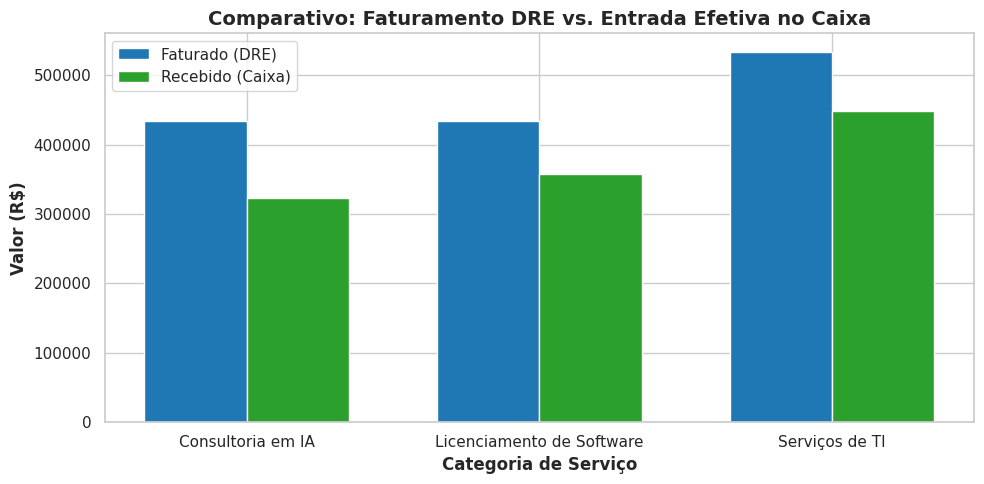

✅ Gráfico gerado e guardado como 'grafico_faturamento_vs_caixa.png'


In [ ]:
# --- 2. GERAR GRÁFICO COMPARATIVO EM PYTHON ---
sns.set_theme(style="whitegrid")
plt.figure(figsize=(10, 5))

# Agrupar valores por categoria para comparação visual rápida
df_resumo = (
    df_conciliado.groupby("categoria")[["valor_faturado", "valor_liquido"]]
    .sum()
    .reset_index()
)

bar_width = 0.35
x = np.arange(len(df_resumo["categoria"]))

plt.bar(
    x - bar_width / 2,
    df_resumo["valor_faturado"],
    width=bar_width,
    label="Faturado (DRE)",
    color="#1f77b4",
)
plt.bar(
    x + bar_width / 2,
    df_resumo["valor_liquido"],
    width=bar_width,
    label="Recebido (Caixa)",
    color="#2ca02c",
)

plt.xlabel("Categoria de Serviço", fontweight="bold")
plt.ylabel("Valor (R$)", fontweight="bold")
plt.title(
    "Comparativo: Faturamento DRE vs. Entrada Efetiva no Caixa",
    fontsize=14,
    fontweight="bold",
)
plt.xticks(x, df_resumo["categoria"])
plt.legend()
plt.tight_layout()

# Guardar imagem do gráfico
plt.savefig("grafico_faturamento_vs_caixa.png", dpi=300)
plt.show()

print("✅ Gráfico gerado e guardado como 'grafico_faturamento_vs_caixa.png'")

In [ ]:
df_resumo_pct = df_resumo.copy()
# Calcular a variação absoluta (gap) e a variação percentual
df_resumo_pct['gap_absoluto'] = df_resumo_pct['valor_faturado'] - df_resumo_pct['valor_liquido']
df_resumo_pct['variacao_percentual'] = (df_resumo_pct['gap_absoluto'] / df_resumo_pct['valor_faturado'] * 100).round(2)

# Formatando para exibição elegante em formato de moeda e percentual
df_exibicao = df_resumo_pct.copy()
df_exibicao['valor_faturado'] = df_exibicao['valor_faturado'].map('R$ {:,.2f}'.format)
df_exibicao['valor_liquido'] = df_exibicao['valor_liquido'].map('R$ {:,.2f}'.format)
df_exibicao['gap_absoluto'] = df_exibicao['gap_absoluto'].map('R$ {:,.2f}'.format)
df_exibicao['variacao_percentual'] = df_exibicao['variacao_percentual'].map('{:.2f}%'.format)

display(df_exibicao)

,categoria,valor_faturado,valor_liquido,gap_absoluto,variacao_percentual
0,Consultoria em IA,"R$ 433,935.84","R$ 323,469.20","R$ 110,466.64",25.46%
1,Licenciamento de Software,"R$ 434,718.02","R$ 358,094.59","R$ 76,623.43",17.63%
2,Serviços de TI,"R$ 533,735.23","R$ 448,836.00","R$ 84,899.23",15.91%


Código para Identificar os Clientes Inadimplentes


In [ ]:
# --- ISOLAR CLIENTES COM MAIOR INADIMPLÊNCIA E ATRASO ---
df_inadimplencia = df_conciliado[df_conciliado["status_pagamento"] == "Inadimplente"].groupby("cliente").agg(
    total_inadimplente=("valor_faturado", "sum"),
    quantidade_faturas=("id_venda", "count")
).reset_index().sort_values(by="total_inadimplente", ascending=False)

# Formatar para exibição limpa
df_inadimplencia_exibicao = df_inadimplencia.copy()
df_inadimplencia_exibicao["total_inadimplente"] = df_inadimplencia_exibicao["total_inadimplente"].map("R$ {:,.2f}".format)

print("=== RANKING DE CLIENTES COM MAIOR INADIMPLÊNCIA ===\n")
print(df_inadimplencia_exibicao.head(10).to_string(index=False))

=== RANKING DE CLIENTES COM MAIOR INADIMPLÊNCIA ===

    cliente total_inadimplente  quantidade_faturas
Cliente_019       R$ 15,479.52                   2
Cliente_008       R$ 14,483.11                   2
Cliente_017       R$ 12,573.87                   1
Cliente_013        R$ 8,653.09                   1
Cliente_010        R$ 7,859.04                   1
Cliente_006        R$ 6,889.75                   1
Cliente_009        R$ 3,053.59                   1
